In [1]:
image_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/scp/tshirts/tshirts-test-kpcentercropped/test/location_4/tshirts/2023-04-24_14-51-30_rgb_zed.png"

keypoint_model_artifact = "tlips/dsd-paper/runs/29zt96n2"
seg_model_artifact = "tlips/dsd-paper-yolo/runs/5v57ni2p"

In [2]:
import wandb 
from keypoint_detection.utils.load_checkpoints import get_model_from_wandb_checkpoint

def get_model_artifact_name_from_run_id(
    run_id: str,
    artifact_type: str = "model" # Assuming the model artifact type is 'model'
) -> str | None:
  
    api = wandb.Api()
    # Get the run object
    run = api.run(run_id)

    # Get all artifacts logged by this run
    logged_artifacts = run.logged_artifacts()

    model_artifact_names = []
    for artifact in logged_artifacts:
        if artifact.type == artifact_type:
            # The artifact.name property typically gives the name and version/alias
            # e.g., "yolov8n_model:v0" or "best_model:latest"
            model_artifact_names.append(artifact.name)
            print(f"Found artifact: {artifact.name} (type: {artifact.type})")
    return model_artifact_names[0] if model_artifact_names else None

def get_segmentation_model_from_wandb_checkpoint(checkpoint_reference: str):
    """
    get a model from a pytorch lightning checkpoint stored on wandb as artifact.

    """

    # download checkpoint locally (if not already cached)
    if wandb.run is None:
        run = wandb.init(project="inference")
    else:
        run = wandb.run
    artifact = run.use_artifact(checkpoint_reference, type="model")
    artifact_dir = artifact.download()
    # list all files in the artifact directory
    from pathlib import Path
    print("Files in artifact directory:")
    for file in Path(artifact_dir).iterdir():
        print(file)

    checkpoint_path = Path(artifact_dir) / "best.pt"
    return load_seg_model_from_checkpoint(checkpoint_path)


import ultralytics
from ultralytics import YOLO
def load_seg_model_from_checkpoint(checkpoint_path: str):
    """
    Load a segmentation model from a checkpoint file.
    
    Args:
        checkpoint_path (str): Path to the checkpoint file.
        
    Returns:
        yolo.models.yolo.YOLO: The loaded YOLO model.
    """
    # Load the YOLO model from the checkpoint
    model = YOLO(checkpoint_path)
    return model



def get_seg_model_from_run(run_id:str):
    artifact = get_model_artifact_name_from_run_id(run_id)
    artifact_path = f"tlips/dsd-paper-yolo/{artifact}"
    model = get_segmentation_model_from_wandb_checkpoint(artifact_path)
    return model



def get_kp_model_from_run(run_id:str):
    artifact = get_model_artifact_name_from_run_id(run_id)
    artifact_path = f"tlips/dsd-paper/{artifact}"
    model = get_model_from_wandb_checkpoint(artifact_path)
    return model




In [3]:

import torch
from keypoint_detection.utils.heatmap import get_keypoints_from_heatmap_batch_maxpool
import numpy as np 
from PIL import Image

def get_keypoints(image_path, model, device="cuda", abs_confidence_threshold=0.1):
    """inference on a single image as if you would load the image from disk or get it from a camera.
    Returns a list of the extracted keypoints for each channel.


    """
    # assert model is in eval mode! (important for batch norm layers)
    model.eval().to(device)
    image = Image.open(image_path).convert("RGB")

    # convert image to tensor with correct shape (channels, height, width) and convert to floats in range [0,1]
    # add batch dimension
    # and move to device
    image = np.array(image).astype(np.float32) / 255.0
    image = torch.from_numpy(image.transpose(2, 0, 1)).unsqueeze(0).to(device)

    # pass through model
    with torch.no_grad():
        heatmaps = model(image).squeeze(0)

    # extract keypoints from heatmaps
    predicted_keypoints = get_keypoints_from_heatmap_batch_maxpool(
        heatmaps.unsqueeze(0), abs_max_threshold=abs_confidence_threshold, max_keypoints=1
    )[0]

    
    # convert keypoints to numpy array
    formatted_keypoints = []
    for channel_keypoints in predicted_keypoints:
        if len(channel_keypoints) > 0:
            formatted_keypoints.append(channel_keypoints[0])
        else:
            formatted_keypoints.append([0,0])
    

    return formatted_keypoints


def get_segmentation_mask(image_path, model):
    """
    Get the segmentation mask for an image using a YOLO model.
    
    Args:
        image_path (str): Path to the input image.
        model (YOLO): The YOLO model for segmentation.
        
    Returns:
        np.ndarray: The segmentation mask as a numpy array.
    """
    # Perform inference on the image
    results = model.predict(source=image_path, save=False, verbose=False)
    # Extract the segmentation mask from the results
    segmask = results[0].masks.data.cpu().numpy()
  
    # drop first dimension  and scale to range 0-255
    segmask = segmask[0] *255
    if segmask is not None:
        return segmask
    else:
        raise ValueError("No segmentation mask found in the results.")



In [4]:
# seg_mdoel = get_seg_model_from_run(seg_model_artifact)
# kp_model = get_kp_model_from_run(keypoint_model_artifact)
# mask = get_segmentation_mask(image_path, seg_mdoel)
# keypoints = get_keypoints(image_path,  kp_model,max_keypoints_per_channel=1)
# # channel last



In [5]:
# https://sashamaps.net/docs/resources/20-colors/
DISTINCT_COLORS = [
    "#e6194B",
    "#3cb44b",
    "#ffe119",
    "#4363d8",
    "#f58231",
    "#911eb4",
    "#42d4f4",
    "#f032e6",
    "#bfef45",
    "#fabed4",
    "#469990",
    "#dcbeff",
    "#9A6324",
    "#fffac8",
    "#800000",
    "#aaffc3",
    "#808000",
    "#ffd8b1",
    "#000075",
    "#ffffff",
    "#000000",
]


In [6]:
import skimage.measure
from PIL import ImageDraw, Image
import matplotlib.pyplot as plt

def draw_seg_mask_contour(image: Image.Image, segmask: np.ndarray, color=(255, 0, 0), thickness=1) -> Image.Image:
    """
    Draw segmentation mask contours on the image.
    
    Args:
        image (Image.Image): The input image.
        segmask (np.ndarray): The segmentation mask with shape (H, W).
        color (tuple): The color of the contour in RGB format.
        thickness (int): The thickness of the contour lines.
        
    Returns:
        Image.Image: The image with the segmentation mask contours drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    
    # Create a draw object
    draw = ImageDraw.Draw(image)
    
    # Find contours in the segmentation mask
    contours = skimage.measure.find_contours(segmask, 0.5)
    
    # Draw each contour
    for contour in contours:
        # Convert contour coordinates to integer
        contour = np.array(contour, dtype=np.int32)
        # flip x,y because skimage uses (row, col) format while PIL uses (x, y)
        contour[:, [0, 1]] = contour[:, [1, 0]]
        # Draw the contour on the image
        draw.line(list(map(tuple, contour)), fill=color, width=thickness)
    
    return image

def draw_seg_mask_blend(image: Image.Image,segmask: np.ndarray,alpha: float = 0.5) -> Image.Image:
    """
    Draw segmentation mask on the image by reducing the alpha  of the background
    Args:
        image (Image.Image): The input image.
        segmask (np.ndarray): The segmentation mask with shape (H, W).
    Returns:
        Image.Image: The image with the segmentation mask drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    # Convert the segmentation mask to a PIL image
    segmask = Image.fromarray(segmask.astype(np.uint8), mode="L")
    # Create a new image with the same size as the input image
    new_image = Image.new("RGBA", image.size, (0, 0, 0, 0))
    # Create a mask for the background
    background_mask = Image.new("L", image.size, 255)
    # Create a mask for the foreground
    foreground_mask = Image.new("L", image.size, 0)
    # Draw the segmentation mask on the foreground mask
    foreground_mask.paste(segmask, (0, 0), segmask)
    # Reduce the alpha of the background
    background_mask = Image.eval(background_mask, lambda x: int(x * alpha))
    # Paste the background and foreground masks on the new image
    new_image.paste(image, (0, 0), background_mask)
    new_image.paste(image, (0, 0), foreground_mask)
    # Convert the new image to RGB mode
    new_image = new_image.convert("RGB")
    # Convert the new image to a numpy array
    return new_image
#     


In [7]:
def draw_keypoints(image: Image.Image, keypoints: np.ndarray, radius: int = 5) -> Image.Image:
    """
    Draw keypoints on the image.
    Args:
        image (Image.Image): The input image.
        keypoints (np.ndarray): The keypoints with shape (N, 2).
        radius (int): The radius of the keypoints.
    Returns:
        Image.Image: The image with the keypoints drawn on it.
    """
    # Convert the image to RGBA mode
    image = image.convert("RGBA")
    
    draw = ImageDraw.Draw(image)

# Draw the keypoints on the image
    for i in range(len(keypoints)):
        if len(keypoints[i]) != 2:
            print(f"Skipping keypoint {i} with invalid shape: {keypoints[i]}")
            continue
        x, y = keypoints[i]
        # Draw a circle around the keypoint
        x, y = keypoints[i]
        # Draw a circle around the keypoint
        draw.ellipse((x - radius, y - radius, x + radius, y + radius), fill=DISTINCT_COLORS[i % len(DISTINCT_COLORS)])

    return image




In [8]:
KP_RANDOM_TEXTURES_MUGS_RUN = "tlips/dsd-paper/runs/kt04wrsb"
KP_RANDOM_TEXTURES_SHOES_RUN = "tlips/dsd-paper/runs/c26497pa"
KP_RANDOM_TEXTURES_TSHIRTS_RUN = "tlips/dsd-paper/runs/pff2qijf"

KP_PROMPT_GEMINI_MUGS_RUN = "tlips/dsd-paper/runs/s5gwjor3"
KP_PROMPT_GEMINI_SHOES_RUN = "tlips/dsd-paper/runs/dl6ksv7b"
KP_PROMPT_GEMINI_TSHIRTS_RUN = "tlips/dsd-paper/runs/29zt96n2"

SEG_RANDOM_TEXTURES_MUGS_RUN = "tlips/dsd-paper-yolo/runs/ola7i6sz"
SEG_RANDOM_TEXTURES_SHOES_RUN = "tlips/dsd-paper-yolo/runs/mjd5800n"
SEG_RANDOM_TEXTURES_TSHIRTS_RUN = "tlips/dsd-paper-yolo/runs/vy3g3o5g"

SEG_PROMPT_GEMINI_MUGS_RUN = "tlips/dsd-paper-yolo/runs/nl4pqdu1"
SEG_PROMPT_GEMINI_SHOES_RUN = "tlips/dsd-paper-yolo/runs/75dm6fa5"
SEG_PROMPT_GEMINI_TSHIRTS_RUN = "tlips/dsd-paper-yolo/runs/5v57ni2p"

tshirt_img_1_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/scp/tshirts/tshirts-test-kpcentercropped/test/location_4/tshirts/2023-04-24_14-51-30_rgb_zed.png"
tshirt_img_2_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/tshirts/tshirts-test-kpcentercropped/test/location_9/tshirts/2023-04-26_09-51-01_rgb_zed.png"
tshirt_img_2_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/tshirts/tshirts-test-kpcentercropped/test/location_3/tshirts/2023-04-24_17-09-13_rgb_zed.png"

mug_img_1_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/mugs/lab-mugs_resized_512x512/images/IMG20240207165401.jpg"
mug_img_2_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/mugs/lab-mugs_resized_512x512/images/IMG20240207165848.jpg"

shoe_img_1_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/shoes/dsd-shoes-real_resized_512x512/images/IMG20240516091446.jpg"
shoe_img_2_path = "/home/tlips/Documents/diffusing-synthetic-data/data/real/shoes/dsd-shoes-real_resized_512x512/images/IMG20240516092658.jpg"


In [12]:
# get the segmask and keypoints for each image 

contour_color = (0, 255, 255)
contour_thickness = 5
keypoint_radius = 12
def visualize(img_path, kp_run, seg_run):
    segmask = get_segmentation_mask(img_path, get_seg_model_from_run(seg_run))
    keypoints = get_keypoints(img_path, get_kp_model_from_run(kp_run))
    vis = draw_seg_mask_contour(Image.open(img_path), segmask, color=contour_color, thickness=contour_thickness)
    vis = draw_keypoints(vis, keypoints, radius=keypoint_radius)
    return vis

tshirt_1_random_vis = visualize(tshirt_img_1_path, KP_RANDOM_TEXTURES_TSHIRTS_RUN, SEG_RANDOM_TEXTURES_TSHIRTS_RUN)
tshirt_2_random_vis = visualize(tshirt_img_2_path, KP_RANDOM_TEXTURES_TSHIRTS_RUN, SEG_RANDOM_TEXTURES_TSHIRTS_RUN)
mug_1_random_vis = visualize(mug_img_1_path, KP_RANDOM_TEXTURES_MUGS_RUN, SEG_RANDOM_TEXTURES_MUGS_RUN)
mug_2_random_vis = visualize(mug_img_2_path, KP_RANDOM_TEXTURES_MUGS_RUN, SEG_RANDOM_TEXTURES_MUGS_RUN)
shoe_1_random_vis = visualize(shoe_img_1_path, KP_RANDOM_TEXTURES_SHOES_RUN, SEG_RANDOM_TEXTURES_SHOES_RUN)
shoe_2_random_vis = visualize(shoe_img_2_path, KP_RANDOM_TEXTURES_SHOES_RUN, SEG_RANDOM_TEXTURES_SHOES_RUN)
# get the segmentation mask and keypoints for each image using diffusion models
tshirt_1_diffusion_vis = visualize(tshirt_img_1_path, KP_PROMPT_GEMINI_TSHIRTS_RUN, SEG_PROMPT_GEMINI_TSHIRTS_RUN)
tshirt_2_diffusion_vis = visualize(tshirt_img_2_path, KP_PROMPT_GEMINI_TSHIRTS_RUN, SEG_PROMPT_GEMINI_TSHIRTS_RUN)
mug_1_diffusion_vis = visualize(mug_img_1_path, KP_PROMPT_GEMINI_MUGS_RUN, SEG_PROMPT_GEMINI_MUGS_RUN)
mug_2_diffusion_vis = visualize(mug_img_2_path, KP_PROMPT_GEMINI_MUGS_RUN, SEG_PROMPT_GEMINI_MUGS_RUN)
shoe_1_diffusion_vis = visualize(shoe_img_1_path, KP_PROMPT_GEMINI_SHOES_RUN, SEG_PROMPT_GEMINI_SHOES_RUN)
shoe_2_diffusion_vis = visualize(shoe_img_2_path, KP_PROMPT_GEMINI_SHOES_RUN, SEG_PROMPT_GEMINI_SHOES_RUN)



Found artifact: run_vy3g3o5g_model:v0 (type: model)


wandb:   1 of 1 files downloaded.  


Files in artifact directory:
/fast_storage_2/symlinked_homes/tlips/Documents/Documents/diffusing-synthetic-data/dsd/experiments/artifacts/run_vy3g3o5g_model:v0/best.pt
Found artifact: model-pff2qijf:v0 (type: model)


wandb: Downloading large artifact model-pff2qijf:v0, 67.33MB. 1 files... 
wandb:   1 of 1 files downloaded.  
Done. 0:0:0.4


Found artifact: run_vy3g3o5g_model:v0 (type: model)


...

wandb: Downloading large artifact model-dl6ksv7b:v0, 67.31MB. 1 files... 
wandb:   1 of 1 files downloaded.  
Done. 0:0:0.4


Found artifact: run_75dm6fa5_model:v0 (type: model)


wandb:   1 of 1 files downloaded.  


Files in artifact directory:
/fast_storage_2/symlinked_homes/tlips/Documents/Documents/diffusing-synthetic-data/dsd/experiments/artifacts/run_75dm6fa5_model:v0/best.pt
Found artifact: model-dl6ksv7b:v0 (type: model)


wandb: Downloading large artifact model-dl6ksv7b:v0, 67.31MB. 1 files... 
wandb:   1 of 1 files downloaded.  
Done. 0:0:0.3


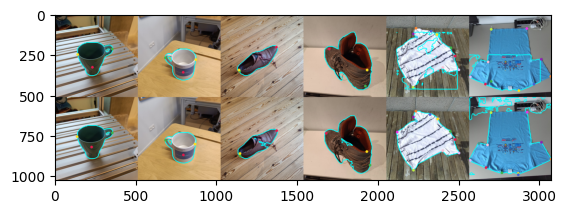

In [10]:

# Create a new image with the same size as the input image

new_image = Image.new("RGBA", (6*512,2*512), (0, 0, 0, 0))
new_image.paste(mug_1_random_vis, (0, 0))
new_image.paste(mug_1_diffusion_vis, (0, 512))
new_image.paste(mug_2_random_vis, (512, 0))
new_image.paste(mug_2_diffusion_vis, (512, 512))
new_image.paste(shoe_1_random_vis, (2*512, 0))
new_image.paste(shoe_1_diffusion_vis, (2*512, 512))
new_image.paste(shoe_2_random_vis, (3*512, 0))
new_image.paste(shoe_2_diffusion_vis, (3*512, 512))
new_image.paste(tshirt_1_random_vis, (4*512, 0))
new_image.paste(tshirt_1_diffusion_vis, (4*512, 512))
new_image.paste(tshirt_2_random_vis, (5*512, 0))
new_image.paste(tshirt_2_diffusion_vis, (5*512, 512))
# Convert the new image to RGB mode
plt.imshow(new_image)
new_image.save("visualization.png")

In [11]:
plt.imshow(tshirt_1_vis)

NameError: name 'tshirt_1_vis' is not defined